# Covariate-adjusted perturbation effects on a genome-scale CD4+ T-cell screen

In a large screen, a target's cells and the control cells rarely come from the same donors or have the
same sequencing depth. A plain comparison with the controls then reports those differences as an effect
of the knockdown. This tutorial estimates effects adjusted for the covariates the screen's authors used,
in two ways, and checks both against the authors' own estimates:

- **`cx.tl.residual_effects`**, per cell (Feng et al., 2026, *Cell Genomics*, [doi:10.1016/j.xgen.2025.101076](https://doi.org/10.1016/j.xgen.2025.101076)): normalise each cell to
  `log1p` counts per 10,000, fit each gene to the covariates on the control cells only, and take a
  target's effect as the average, over its cells, of observed minus fitted expression. One pass over
  the raw counts on disk.
- **`cx.nb_glm_test`** on pseudo-bulk: counts summed per guide and donor, fitted with a negative binomial
  model, as the authors did with DESeq2.

Both adjust only for covariates that were recorded. If a target's cells may differ from the controls
in ways no recorded covariate captures (hidden confounding, such as an unrecorded batch or cell
state), use [causarray](https://causarray.readthedocs.io) (Du *et al.*, 2026, *Briefings in
Bioinformatics*, [doi:10.1093/bib/bbag175](https://doi.org/10.1093/bib/bbag175)), which estimates
unmeasured confounders and adjusts for them. Like DESeq2, it works on single cells or on pseudo-bulk
counts such as those from `cx.pb.aggregate(..., method='sum')`.

> **Key results**
>
> - The negative binomial model on pseudo-bulk reproduces the authors' estimates (median per-target
>   correlation 0.997). Where it differs, the authors had dropped a guide they judged ineffective.
> - `residual_effects` agrees closely as well (median r 0.84; 99.4% of the authors' hits have the same
>   sign) and covers all 12,203 targets in about a minute, where the negative binomial model needs about
>   30 minutes for 500.
> - `residual_effects` finds about twice as many hits as the authors. On fake targets made of control
>   guides, its robust null is calibrated for a typical target, and most of its extra hits look real.

**Data.** Resting CD4+ T cells from all four donors of the genome-scale CRISPRi Perturb-seq screen of
Zhu, Dann *et al.* (bioRxiv 2025, [doi:10.64898/2025.12.23.696273](https://doi.org/10.64898/2025.12.23.696273)): 7.4 million cells, 18,130 genes, 12,636 targeted genes. The
authors published their estimates, made with DESeq2 on counts summed per guide and donor.

- **Part 1** prepares the data: keep cells with one guide, combine the donors, sum counts per guide and
  donor.
- **Part 2** estimates effects with the authors' covariates and compares them with the authors'
  estimates.
- **Part 3** checks calibration on fake targets made of control guides.

Terms used throughout: a *target* is a knocked-down gene; *control cells* carry a non-targeting guide;
a *hit* is a gene whose Benjamini–Hochberg adjusted p-value for a target is below 0.1.

In [1]:
import os
import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
# Progress bars off, so the saved notebook keeps only crispyx's summary lines.
os.environ.setdefault('TQDM_DISABLE', '1')
warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', message='A worker stopped while some jobs')
import crispyx as cx

DATA_DIR = ROOT / 'data' / 'gwcd4i'
OUTPUT_DIR = Path('tutorial_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DONORS = ['D1', 'D2', 'D3', 'D4']

cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
print(f'crispyx {cx.__version__}, {cores} cores')

steps = []


@contextmanager
def measured(step):
    # record a step's wall time and this process's peak memory while it runs
    with cx.Profiler(timing=True, sampling=True, memory_method='rss', sample_interval=0.5) as profiler:
        yield
    stats = profiler.get_stats()
    minutes = stats['timing']['total_seconds'] / 60
    peak_gb = stats['memory']['peak_mb'] / 1024
    steps.append({'step': step, 'wall time (min)': round(minutes, 1), 'peak RSS (GB)': round(peak_gb, 1)})
    print(f'{step}: {minutes:.1f} min, peak RSS {peak_gb:.1f} GB')


@contextmanager
def warnings_as_messages():
    # print crispyx's warnings by message only: the default banner names the source file
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        warnings.simplefilter('ignore', DeprecationWarning)
        yield
    for message in dict.fromkeys(f'{w.category.__name__}: {w.message}' for w in caught):
        print(message)

crispyx 0.1.10, 32 cores


## Get the data

The files are public (MIT licence) in the S3 bucket `genome-scale-tcell-perturb-seq`; no account is
needed. Each donor's file holds every captured cell, 119–143 GB of raw counts (540 GB for the four).
Run once, from the repository root (this cell is not executed here):

```bash
mkdir -p data/gwcd4i && cd data/gwcd4i
BUCKET=https://genome-scale-tcell-perturb-seq.s3.amazonaws.com/marson2025_data
for donor in D1 D2 D3 D4; do curl -O "$BUCKET/${donor}_Rest.assigned_guide.h5ad"; done
curl -O "$BUCKET/GWCD4i.DE_stats.h5ad"             # the authors' results, 16.8 GB
curl -O "$BUCKET/GWCD4i.DE_stats.by_donors.h5mu"   # the same per pair of donors, 16.9 GB
```

# Part 1 — Prepare the data

## 1. Keep cells with one resolved guide

Each file also holds cells with no guide or several guides, and cells flagged as low quality.
`cx.write_filtered_subset` streams the cells to keep into a new file. The mask is built from `obs` alone
(`cx.load_obs`), without reading the counts.

In [2]:
filtered = {}
with measured('keep guide-resolved cells (4 files)'):
    for donor in DONORS:
        source = DATA_DIR / f'{donor}_Rest.assigned_guide.h5ad'
        obs = cx.load_obs(source)
        keep = (
            obs['guide_type'].eq('non-targeting')
            | (obs['guide_type'].eq('targeting') & obs['perturbed_gene_name'].notna())
        ) & ~obs['low_quality'].astype(bool)
        filtered[donor] = OUTPUT_DIR / f'{donor}.h5ad'
        with warnings_as_messages():
            cx.write_filtered_subset(
                source,
                cell_mask=keep.to_numpy(),
                gene_mask=np.ones(len(cx.load_var(source)), dtype=bool),
                output_path=filtered[donor],
            )
        print(f'{donor}: kept {keep.sum():,} of {len(obs):,} cells')

D1: kept 1,752,037 of 3,074,496 cells
D2: kept 1,983,457 of 2,940,194 cells
D3: kept 1,901,710 of 2,778,524 cells
D4: kept 1,749,091 of 2,693,903 cells
keep guide-resolved cells (4 files): 11.2 min, peak RSS 6.7 GB


## 2. Combine the donors

`cx.pp.concat_h5ad` streams the four files into one and records each cell's file in `obs['donor']`.
`shared_cells='error'` checks that no cell appears in two files.

> **Watch out:** the files do not list their genes in the same order (D3 and D4 differ from D1, as the
> first line of the output shows). `concat_h5ad` matches genes by name. Stacking the matrices as they
> are would silently give every cell of D3 and D4 the wrong gene names.

In [3]:
merged_path = OUTPUT_DIR / 'CD4T_Rest.h5ad'
gene_order = {donor: list(cx.load_var(filtered[donor]).index) for donor in DONORS}
print('same gene order as D1:', {donor: gene_order[donor] == gene_order['D1'] for donor in DONORS})
with measured('concatenate the donors'), warnings_as_messages():
    merged = cx.pp.concat_h5ad(
        [filtered[donor] for donor in DONORS],
        output_path=merged_path, label='donor', shared_cells='error',
    )
merged

same gene order as D1: {'D1': True, 'D2': True, 'D3': False, 'D4': False}
[cx] pp.concat_h5ad: Done  7386295 cells × 18130 genes
[cx] pp.concat_h5ad: Saving → tutorial_outputs/CD4T_Rest.h5ad
concatenate the donors: 7.3 min, peak RSS 9.1 GB


AnnData(path=tutorial_outputs/CD4T_Rest.h5ad, mode='r')

## 3. Labels

Each cell's label is its target, or `non-targeting` for control cells. It is passed to
`residual_effects` as a `pd.Series` indexed by cell, so nothing is written to the file. Part 3 uses the
same mechanism to relabel some control cells as fake targets.

In [4]:
obs = cx.load_obs(merged_path)
is_control = obs['guide_type'].eq('non-targeting')
labels = (
    obs['perturbed_gene_name'].astype(object)
    .where(~is_control, 'non-targeting')
    .rename('perturbation')
)
print(f'{len(obs):,} cells, {labels.nunique() - 1:,} targeted genes, {is_control.sum():,} control cells')

7,386,295 cells, 12,636 targeted genes, 313,989 control cells


## 4. Sum counts per guide and donor

The authors' model works on pseudo-bulk samples: the counts of all cells from one donor carrying the
same guide, summed. `cx.pb.aggregate` streams the file once and keeps units of at least 5 cells, as the
authors did.

`cx.write_obs` then adds what the model needs to `obs`, without rewriting the counts: each unit's
target, looked up from its guide, and log10 of its number of cells, one of the authors' covariates.

In [5]:
with measured('sum counts per guide and donor'):
    pseudobulk = cx.pb.aggregate(
        merged_path, groupby=['guide_id', 'donor'], method='sum', min_cells=5,
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'CD4T_Rest_guide_donor.h5ad',
    )
units = cx.load_obs(pseudobulk.path)
guide_target = labels.groupby(obs['guide_id'].astype(str)).first()
units['target'] = units['guide_id'].astype(str).map(guide_target)
units['log10_n_cells'] = np.log10(units['n_cells'].astype(float))
cx.write_obs(pseudobulk.path, units)
n_units = units['target'].value_counts()
print(f"{len(units):,} guide x donor units: {n_units['non-targeting']:,} of control guides; "
      f"{(n_units.drop('non-targeting') >= 3).sum():,} targets with at least 3 units")

[cx] pb.aggregate: chunk_size=4096 (auto)
[cx] pb.aggregate accumulator: estimated disk usage: 11.9 GB (144.2 GB free)
[cx] pb.aggregate: estimated disk usage: 13.1 GB (144.2 GB free)
[cx] pb.aggregate: obs columns that vary within a profile are not carried over: ['lane_id', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'top_guide_UMI_counts', 'PuroR']
[cx] pb.aggregate: 81846 profiles × 18130 genes
[cx] pb.aggregate: Saving → tutorial_outputs/CD4T_Rest_guide_donor.h5ad
sum counts per guide and donor: 7.1 min, peak RSS 29.5 GB
81,846 guide x donor units: 3,387 of control guides; 11,611 targets with at least 3 units


# Part 2 — Effects with the authors' covariates

The authors fitted `~ log10_n_cells + donor_id + target` (their code:
[GWT_perturbseq_analysis_2025](https://github.com/emdann/GWT_perturbseq_analysis_2025)). The number of
cells describes a pseudo-bulk unit, not a cell, so per cell `residual_effects` adjusts for donor only.

## 5. `residual_effects`, per cell

`null` sets how each effect is turned into a z-score:

- `'robust'` (used here) estimates each gene's noise from how much its effect varies across targets.
  It assumes most targets leave a given gene unchanged, which holds in a genome-wide screen.
- `'model'` uses the control cells' scatter around the fit. It treats cells as independent, but cells
  that share a guide or a donor are not; part 3 shows what that does.

Both noise estimates are saved, so either z-score can be computed later without another pass.

In [6]:
with measured('residual_effects, per cell'):
    per_cell = cx.tl.residual_effects(
        merged_path, labels, 'non-targeting', covariates=['donor'], null='robust',
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'cd4t_residual_effects.h5ad',
    )
per_cell

[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest.h5ad
[cx] residual_effects: 433 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'JAK1', 'HGS', 'TRIM11', 'VIRMA', 'RPS8', 'SAMM50', 'DCTN5', 'TTC27', 'RPL13']
[cx] residual_effects: 12,203 perturbations, 313,989 control cells, design: 4 columns
[cx] residual_effects: estimated disk usage: 7.8 GB (132.3 GB free)
[cx] residual_effects: 12,203 perturbations x 18,130 genes (7,976 tested), robust null
[cx] residual_effects: Saving → tutorial_outputs/cd4t_residual_effects.h5ad
residual_effects, per cell: 1.2 min, peak RSS 23.0 GB


AnnData(path=tutorial_outputs/cd4t_residual_effects.h5ad, mode='r')

The result is an on-disk `AnnData` with targets as rows and genes as columns:

| Where | What |
|---|---|
| `X` | the effect: a difference in mean `log1p(CP10k)` (natural log), **not** a log2 fold change |
| `layers` | `z_score`, `pvalue` and `pvalue_adj` (Benjamini–Hochberg within each target) |
| `obs` | cells per target and genes tested |
| `var` | control mean, both noise estimates, and `tested` (control mean above 0.1, as in Feng et al.) |

In [7]:
per_cell.backed.var.head()

,control_mean,residual_sd,robust_sd,tested
gene_name,,,,
TSPAN6,0.000071,0.007653,0.000566,False
TNMD,0.000002,0.001259,0.000041,False
DPM1,0.789105,0.612100,0.759365,True
SCYL3,0.264902,0.439079,0.455009,True
C1orf112,0.382648,0.552633,0.891416,True


## 6. The authors' model on pseudo-bulk

`cx.nb_glm_test` fits a negative binomial model to each target's units together with the control
units, with the authors' design: log10 cells per unit, donor and target. `size_factor_method='deseq2'`
normalises library size the way DESeq2 does.

Each target is a separate fit that includes all 3,387 control units, which makes this slow: about 30
minutes for 500 targets on 32 cores, against about a minute for every target with `residual_effects`.
The 500 targets are picked at random.

In [8]:
testable = n_units.drop('non-targeting')
subset = sorted(np.random.default_rng(0).choice(testable.index[testable >= 3].to_numpy(), 500, replace=False))
with measured('nb_glm_test, pseudo-bulk, 500 targets'):
    nb_glm = cx.nb_glm_test(
        pseudobulk.path, perturbation_column='target', control_label='non-targeting',
        covariates=['log10_n_cells', 'donor'], perturbations=subset, size_factor_method='deseq2',
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'cd4t_nb_glm_500.h5ad',
    )

[cx] nb_glm_test: chunk_size=256 (auto)
[cx] nb_glm_test: estimated disk usage: 1.7 GB (125.2 GB free)
[cx] NB-GLM DE: 500/500 perturbations complete, mean 12071/18130 genes tested (67%)
[cx] nb_glm_test: Saving → tutorial_outputs/cd4t_nb_glm_500.h5ad
nb_glm_test, pseudo-bulk, 500 targets: 29.7 min, peak RSS 16.1 GB


## 7. Compare with the authors' estimates

`GWCD4i.DE_stats.h5ad` holds the authors' DESeq2 results for every target and culture condition. We use
the resting-state targets and genes both analyses tested, matched by gene symbol. `residual_effects`
reports differences of `log1p(CP10k)` and the negative binomial model log2 fold changes, so we compare
z-scores and signs, not effect sizes. For each estimate:

- **median r**: for each target, the correlation between its z-scores and the authors'; then the
  median over targets.
- **same sign on paper hits**: how often the authors' hits get the same direction.
- **|z| > 3 on paper non-hits**: how often a strong effect is reported where the authors report none.
  Pure noise would give 0.27%.
- **hits per target**, next to the authors' number for the same targets and genes.

In [9]:
def residual_z(result, null):
    # targets, genes, z-scores and BH-adjusted p-values of a residual_effects result under either null
    with h5py.File(result.path, 'r') as handle:
        effect = handle['X'][:]
    backed = result.backed
    var, n_cells = backed.var, backed.obs['n_cells'].to_numpy()
    spread = var['robust_sd' if null == 'robust' else 'residual_sd'].to_numpy()
    use = var['tested'].to_numpy() & (spread > 0)
    z, q = np.full_like(effect, np.nan), np.full_like(effect, np.nan)
    z[:, use] = effect[:, use] * np.sqrt(n_cells)[:, None] / spread[use]
    q[:, use] = stats.false_discovery_control(2 * stats.norm.sf(np.abs(z[:, use])), axis=1)
    return pd.Index(backed.obs_names), pd.Index(backed.var_names), z, q


def nb_glm_z(result):
    # targets, genes, z-scores and BH-adjusted p-values of an nb_glm_test result
    with h5py.File(result.result_path, 'r') as handle:
        z, q = handle['layers/z_score'][:], handle['layers/pvalue_adj'][:]
        index = lambda group: pd.Index(group[group.attrs['_index']][:].astype(str))
        return index(handle['obs']), index(handle['var']), z, q


def column(group, key):
    # one obs/var column of an h5ad group, decoding categoricals
    item = group[key]
    if isinstance(item, h5py.Group):
        return item['categories'][:].astype(str)[item['codes'][:]]
    values = item[:]
    return values.astype(str) if values.dtype.kind in 'SO' else values


def paper_table(path):
    # resting-state rows of the authors' DESeq2 results
    with h5py.File(path, 'r') as handle:
        names = column(handle['obs'], 'target_contrast_gene_name')
        rows = np.flatnonzero(column(handle['obs'], 'culture_condition') == 'Rest')
        rows = rows[~pd.Index(names[rows]).duplicated(keep=False)]
        # dense, uncompressed layers: one sequential read each, then the rows we need
        z, q = (handle['layers'][name][:][rows] for name in ('zscore', 'adj_p_value'))
        return pd.Index(names[rows]), pd.Index(column(handle['var'], 'gene_name')), z, q


def on(estimate, targets, genes):
    # z and q of an estimate for the given targets and genes
    est_targets, est_genes, z, q = estimate
    rows, cols = est_targets.get_indexer(targets), est_genes.get_indexer(genes)
    return z[rows][:, cols], q[rows][:, cols]


def per_target_r(a, b):
    # Pearson r of each row of a with the same row of b, over genes finite in both
    ok = np.isfinite(a) & np.isfinite(b)
    n = np.maximum(ok.sum(axis=1, keepdims=True), 1)
    a = np.where(ok, a - np.where(ok, a, 0.0).sum(axis=1, keepdims=True) / n, 0.0)
    b = np.where(ok, b - np.where(ok, b, 0.0).sum(axis=1, keepdims=True) / n, 0.0)
    return (a * b).sum(axis=1) / np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))


paper = paper_table(DATA_DIR / 'GWCD4i.DE_stats.h5ad')
estimates = {
    'residual_effects, robust null': residual_z(per_cell, 'robust'),
    'residual_effects, model null': residual_z(per_cell, 'model'),
    "nb_glm_test (the paper's model)": nb_glm_z(nb_glm),
}
genes = paper[1].intersection(estimates['residual_effects, robust null'][1])

In [10]:
def agreement(name, targets):
    z, q = on(estimates[name], targets, genes)
    paper_z, paper_q = on(paper, targets, genes)
    hits, non_hits = paper_q < 0.1, (paper_q >= 0.1) & np.isfinite(paper_z)
    ok = hits & np.isfinite(z)
    return {
        'targets': len(targets),
        'median r': np.nanmedian(per_target_r(z, paper_z)),
        'same sign on paper hits': np.mean(np.sign(z[ok]) == np.sign(paper_z[ok])),
        '|z| > 3 on paper non-hits': np.mean(np.abs(z[non_hits & np.isfinite(z)]) > 3),
        'hits per target': (q < 0.1).sum(axis=1).mean(),
        'paper hits per target': hits.sum(axis=1).mean(),
    }


all_targets = paper[0].intersection(estimates['residual_effects, robust null'][0])
subset_targets = all_targets.intersection(estimates["nb_glm_test (the paper's model)"][0])
comparison = pd.DataFrame({
    ('all targets', 'residual_effects, robust null'): agreement('residual_effects, robust null', all_targets),
    ('all targets', 'residual_effects, model null'): agreement('residual_effects, model null', all_targets),
    ('500 targets', 'residual_effects, robust null'): agreement('residual_effects, robust null', subset_targets),
    ('500 targets', "nb_glm_test (the paper's model)"): agreement("nb_glm_test (the paper's model)", subset_targets),
}).T
print(f'{len(genes):,} genes tested in both analyses')
comparison.round(3)

10,282 genes tested in both analyses


targets  median r  \
all targets residual_effects, robust null    10973.0     0.841   
            residual_effects, model null     10973.0     0.806   
500 targets residual_effects, robust null      467.0     0.844   
            nb_glm_test (the paper's model)    467.0     0.997   

                                             same sign on paper hits  \
all targets residual_effects, robust null                      0.994   
            residual_effects, model null                       0.994   
500 targets residual_effects, robust null                      0.997   
            nb_glm_test (the paper's model)                    1.000   

                                             |z| > 3 on paper non-hits  \
all targets residual_effects, robust null                        0.010   
            residual_effects, model null                         0.044   
500 targets residual_effects, robust null                        0.009   
            nb_glm_test (the paper's model)                      0.003   

                                             hits per target  \
all targets residual_effects, robust null            108.139   
            residual_effects, model null             481.424   
500 targets residual_effects, robust null             83.077   
            nb_glm_test (the paper's model)           41.452   

                                             paper hits per target  
all targets residual_effects, robust null                   53.844  
            residual_effects, model null                    53.844  
500 targets residual_effects, robust null                   43.084  
            nb_glm_test (the paper's model)                 43.084

The negative binomial model reproduces the authors' estimates almost exactly, and calls about as many
hits. The figure shows it target by target: nearly every target has r close to 1 with the authors.
The 32 targets below 0.95 are exactly those where the authors used one guide and we use two, because
they dropped a guide they judged ineffective.

`residual_effects` agrees closely, but it is a different estimator: a difference of mean `log1p(CP10k)`
over cells, not a model of summed counts. It also finds about twice as many hits (108 per target
against the authors' 54). Part 3 asks whether the extra hits are real.

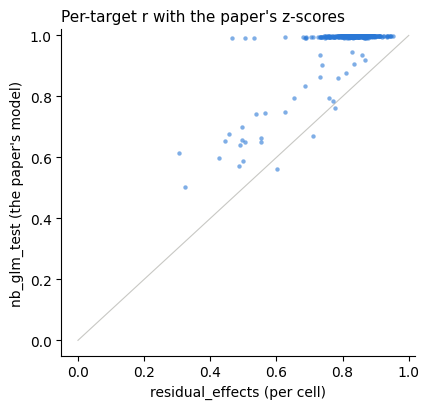

In [11]:
paper_z = on(paper, subset_targets, genes)[0]
r_residual = per_target_r(on(estimates['residual_effects, robust null'], subset_targets, genes)[0], paper_z)
r_nb = per_target_r(on(estimates["nb_glm_test (the paper's model)"], subset_targets, genes)[0], paper_z)
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(r_residual, r_nb, s=10, color='#2a78d6', alpha=0.6, linewidths=0)
ax.plot([0, 1], [0, 1], color='#c8c8c4', linewidth=0.8, zorder=0)
ax.set_xlim(-0.05, 1.02)
ax.set_ylim(-0.05, 1.02)
ax.set_xlabel('residual_effects (per cell)')
ax.set_ylabel("nb_glm_test (the paper's model)")
ax.set_title("Per-target r with the paper's z-scores", loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

A knockdown should lower its own target gene. Among targets whose own gene `residual_effects` tests:

In [12]:
targets_i, genes_i, z_main, _ = estimates['residual_effects, robust null']
with h5py.File(per_cell.path, 'r') as handle:
    effect_main = handle['X'][:]
own = genes_i.get_indexer(targets_i)
tested = per_cell.backed.var['tested'].to_numpy()
measured_own = (own >= 0) & tested[np.maximum(own, 0)]
own_effect = effect_main[np.flatnonzero(measured_own), own[measured_own]]
print(f'{measured_own.sum():,} targets: own-gene effect negative for {np.mean(own_effect < 0):.1%}, '
      f'median {np.median(own_effect):.2f} (log1p CP10k)')

7,257 targets: own-gene effect negative for 97.7%, median -0.25 (log1p CP10k)


# Part 3 — Calibration on fake targets

A test is calibrated when it rarely reports hits where there is no effect. Following the authors' own
check (their Suppl. Fig. 4B), fake targets are made of control guides. The control guides whose cell
counts lie between the 5th and 95th percentile are shuffled, and half of them are paired into fake
targets of two guides, the size of a typical real target. All other control guides stay controls. A
fake target has no knockdown, but its cells keep the differences between guides and donors that real
targets have.

Five random splits go through `residual_effects`, together with the real targets so that the robust null
sees the same spread as in part 2; the first split also goes through the negative binomial model. For a
calibrated test, 5% of p-values fall below 0.05 and 0.27% of |z| above 3.

In [13]:
guide = obs['guide_id'].astype(str)
control_guide_cells = guide[is_control].value_counts()
low, high = np.percentile(control_guide_cells, [5, 95])
eligible = np.sort(control_guide_cells.index[(control_guide_cells >= low) & (control_guide_cells <= high)])


def fake_targets(split):
    # half of the eligible control guides, paired at random into fake targets of two guides
    chosen = np.random.default_rng(split).permutation(eligible)[: len(eligible) // 4 * 2]
    return pd.Series({g: f'fake{split}_{i // 2:03d}' for i, g in enumerate(chosen)})


def calibration(z, q):
    finite = np.isfinite(z)
    hits = (q < 0.1).sum(axis=1)
    return {
        'fake targets': len(z), 'with any hit': np.mean(hits > 0), 'median hits': np.median(hits),
        'mean hits': hits.mean(),
        'p < 0.05': np.mean(2 * stats.norm.sf(np.abs(z[finite])) < 0.05),
        '|z| > 3': np.mean(np.abs(z[finite]) > 3),
    }


null_rows, fake_hits = [], {}
for split in range(5):
    pairs = fake_targets(split)
    split_labels = labels.where(~guide.isin(pairs.index), guide.map(pairs))
    with measured(f'residual_effects, fake targets (split {split})'):
        result = cx.tl.residual_effects(
            merged_path, split_labels, 'non-targeting', covariates=['donor'], null='robust',
            gene_name_column='gene_name', output_path=OUTPUT_DIR / f'null_split{split}.h5ad', verbose=0,
        )
    for null in ('robust', 'model'):
        targets_i, _, z, q = residual_z(result, null)
        fake = targets_i.str.startswith(f'fake{split}_')
        null_rows.append({'method': f'residual_effects, {null} null', 'split': split, **calibration(z[fake], q[fake])})
        if split == 0:
            fake_hits[f'residual_effects, {null} null'] = pd.Series((q[fake] < 0.1).sum(axis=1), index=targets_i[fake])

# the paper's model on the fake targets of the first split
pairs = fake_targets(0)
units['fake_target'] = units['guide_id'].astype(str).map(pairs).fillna(units['target'])
cx.write_obs(pseudobulk.path, units)
with measured('nb_glm_test, fake targets (split 0)'):
    nb_null = cx.nb_glm_test(
        pseudobulk.path, perturbation_column='fake_target', control_label='non-targeting',
        covariates=['log10_n_cells', 'donor'], perturbations=sorted(set(pairs)), size_factor_method='deseq2',
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'null_split0_nb_glm.h5ad', verbose=0,
    )
targets_i, _, z, q = nb_glm_z(nb_null)
null_rows.append({'method': "nb_glm_test (the paper's model)", 'split': 0, **calibration(z, q)})
fake_hits["nb_glm_test (the paper's model)"] = pd.Series((q < 0.1).sum(axis=1), index=targets_i)
pd.DataFrame(null_rows).groupby('method', sort=False).mean().drop(columns='split').round(4)

residual_effects, fake targets (split 0): 1.3 min, peak RSS 34.4 GB
residual_effects, fake targets (split 1): 1.2 min, peak RSS 42.2 GB
residual_effects, fake targets (split 2): 1.1 min, peak RSS 42.0 GB
residual_effects, fake targets (split 3): 1.1 min, peak RSS 41.9 GB
residual_effects, fake targets (split 4): 1.2 min, peak RSS 43.4 GB
nb_glm_test, fake targets (split 0): 7.6 min, peak RSS 35.4 GB


,fake targets,with any hit,median hits,mean hits,p < 0.05,|z| > 3
method,,,,,,
"residual_effects, robust null",220.0,0.4755,0.2,25.3473,0.0470,0.0046
"residual_effects, model null",220.0,1.0000,188.3,302.3164,0.1268,0.0316
nb_glm_test (the paper's model),220.0,0.4045,0.0,9.4909,0.0458,0.0034


With the robust null, `residual_effects` is calibrated for a typical fake target: 4.7% of p-values
below 0.05 and a median of 0.2 hits, close to the authors' model (4.6%, no hits). The model null is not:
every fake target gets hits, about 300 on average, because the cells of one guide or one donor are not
independent.

Still, about half of the fake targets get at least one hit with either method, and the mean is far
above the median. A few fake targets carry almost all of them:

In [14]:
fake_hits = pd.DataFrame(fake_hits)
share_top = {m: fake_hits[m].nlargest(len(fake_hits) // 20).sum() / fake_hits[m].sum() for m in fake_hits}
print('share of all fake-target hits in the 5% of fake targets with the most:',
      {m: f'{v:.0%}' for m, v in share_top.items()})
top = fake_hits.sort_values("nb_glm_test (the paper's model)", ascending=False).head(5)
top.assign(guides=[', '.join(pairs.index[pairs == name]) for name in top.index])

share of all fake-target hits in the 5% of fake targets with the most: {'residual_effects, robust null': '93%', 'residual_effects, model null': '29%', "nb_glm_test (the paper's model)": '86%'}


,"residual_effects, robust null","residual_effects, model null",nb_glm_test (the paper's model),guides
fake0_177,32,1709,596,"NTC-499, NTC-532"
fake0_010,3926,4757,427,"NTC-192, NTC-326"
fake0_074,1159,2396,221,"NTC-604, NTC-050"
fake0_207,0,582,146,"NTC-819, NTC-938"
fake0_081,1,213,127,"NTC-518, NTC-304"


The three fake targets with the most hits under the authors' model also stand out with
`residual_effects` (32 to 3,926 hits). A non-targeting guide can still act on the cell, for example
through an off-target site, so these hits are probably real effects of those guides rather than noise
in the test.

As a rough bound, suppose every real target picked up as many false hits as an average fake target: 25
for `residual_effects` and 9 for the authors' model. That would be about a quarter of
`residual_effects`' 108 hits per target, and about a sixth of the authors' 54. So most of the extra hits
are real effects, but `residual_effects` reports false hits somewhat more readily (|z| > 3 for 0.46% of
fake-target genes, against 0.34%).

## Resources

Wall time and peak memory of this notebook's process for each step. The peak includes the targets ×
genes matrices the notebook keeps for its comparisons.

In [15]:
resources = pd.DataFrame(steps).set_index('step')
resources.loc['total'] = [resources['wall time (min)'].sum(), resources['peak RSS (GB)'].max()]
resources

,wall time (min),peak RSS (GB)
step,,
keep guide-resolved cells (4 files),11.2,6.7
concatenate the donors,7.3,9.1
sum counts per guide and donor,7.1,29.5
"residual_effects, per cell",1.2,23.0
"nb_glm_test, pseudo-bulk, 500 targets",29.7,16.1
"residual_effects, fake targets (split 0)",1.3,34.4
"residual_effects, fake targets (split 1)",1.2,42.2
"residual_effects, fake targets (split 2)",1.1,42.0
"residual_effects, fake targets (split 3)",1.1,41.9


## Takeaways

- **To reproduce a DESeq2 pseudo-bulk analysis**, sum counts with `cx.pb.aggregate` and fit the same
  design with `cx.nb_glm_test`. Here it matches the authors' estimates (median r 0.997), at about 4
  seconds per target on 32 cores.
- **For a fast genome-wide pass**, use `cx.tl.residual_effects` with `null='robust'`: about a minute for
  all 12,203 targets, close agreement with the authors (median r 0.84, 99.4% same sign on their hits),
  and calibrated on fake targets.
- **Use `null='robust'` on single cells**, not `null='model'`, which reports hits for every fake
  target.
- **`residual_effects` finds about twice as many hits** as the authors' model. Most look real, but it
  reports false hits somewhat more readily.
- **Some non-targeting guides seem to have effects of their own.** Fake targets built from them get
  hundreds of hits with both methods.